<a href="https://colab.research.google.com/github/Team-JAZL/Fruitects-IS-DPC/blob/feat%2Fintelligent-systems-model-preparation/benchmarking/fruit_type_identifier_model_processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install kaggle library
!pip install -q kaggle

# Create kaggle directory and move the uploaded json file there
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the specific dataset
!kaggle datasets download -d amdatas/fruits-diseases-classification-dataset

# Unzip the downloaded dataset
!unzip -q fruits-diseases-classification-dataset.zip -d raw_dataset
print("Dataset downloaded and extracted successfully!")

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/amdatas/fruits-diseases-classification-dataset
License(s): MIT
fruits-diseases-classification-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace raw_dataset/FRUITS DISEASES CLASSIFICATION/APPLE/Blotch_Apple/_0_106.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
Dataset downloaded and extracted successfully!


In [2]:
import os
import shutil

# Define the source and destination paths
# Note: Adjust the 'source_dir' if the unzipped path has a nested folder structure
source_dir = 'raw_dataset/FRUITS DISEASES CLASSIFICATION'
base_dest_dir = 'organized_dataset'

target_fruits = ['Apple', 'Guava', 'Mango']

# Create the new directory structure
for fruit in target_fruits:
    os.makedirs(os.path.join(base_dest_dir, fruit), exist_ok=True)

# Walk through the original dataset and copy images
if os.path.exists(source_dir):
    for root, dirs, files in os.walk(source_dir):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                file_path = os.path.join(root, file)

                # Check which fruit the folder belongs to
                folder_name = os.path.basename(root)
                for fruit in target_fruits:
                    if fruit.lower() in folder_name.lower():
                        dest_path = os.path.join(base_dest_dir, fruit, file)
                        # To avoid duplicate names, we append a unique hash or the folder name
                        unique_filename = f"{folder_name}_{file}"
                        dest_path = os.path.join(base_dest_dir, fruit, unique_filename)
                        shutil.copy2(file_path, dest_path)
                        break

    print("Data successfully reorganized into Apple, Guava, and Mango classes.")
else:
    print(f"Directory {source_dir} not found. Please check the unzipped folder name.")

Data successfully reorganized into Apple, Guava, and Mango classes.


In [3]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_SIZE = (224, 224)
SEED = 42

# Create a full dataset
print("Loading Training Data...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    base_dest_dir,
    validation_split=0.3, # 70% for training, 30% for val/test
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

print("\nLoading Validation/Test Data...")
val_test_dataset = tf.keras.utils.image_dataset_from_directory(
    base_dest_dir,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)
class_names = train_dataset.class_names
print(f"\nClasses identified: {class_names}")

# Split the 30% validation pool evenly into Validation (15%) and Testing (15%)
val_batches = tf.data.experimental.cardinality(val_test_dataset)
val_dataset = val_test_dataset.take(val_batches // 2)
test_dataset = val_test_dataset.skip(val_batches // 2)

# Optimize performance
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.cache().prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.cache().prefetch(buffer_size=AUTOTUNE)

Loading Training Data...
Found 1438 files belonging to 3 classes.
Using 1007 files for training.

Loading Validation/Test Data...
Found 1438 files belonging to 3 classes.
Using 431 files for validation.

Classes identified: ['Apple', 'Guava', 'Mango']


In [4]:
from tensorflow.keras.applications import ResNet50, MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

def build_model(base_model_type, num_classes):
    input_shape = IMG_SIZE + (3,)

    if base_model_type == 'resnet50':
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
        # ResNet50 requires specific preprocessing
        preprocess_input = tf.keras.applications.resnet50.preprocess_input
    elif base_model_type == 'mobilenetv2':
        base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
        # MobileNetV2 requires inputs between [-1, 1]
        preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input
    else:
        raise ValueError("Invalid model type")

    # Freeze the base model
    base_model.trainable = False

    # Create the model architecture
    inputs = tf.keras.Input(shape=input_shape)
    x = preprocess_input(inputs)
    x = base_model(x, training=False)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.2)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs, outputs)

    model.compile(optimizer=Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

resnet_model = build_model('resnet50', len(class_names))
mobilenet_model = build_model('mobilenetv2', len(class_names))

--- Training ResNet-50 ---
Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 38s 441ms/step - accuracy: 0.8391 - loss: 0.3895 - val_accuracy: 0.9866 - val_loss: 0.0572
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 95ms/step - accuracy: 0.9921 - loss: 0.0449 - val_accuracy: 0.9866 - val_loss: 0.0327
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 96ms/step - accuracy: 0.9980 - loss: 0.0237 - val_accuracy: 0.9911 - val_loss: 0.0229
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 96ms/step - accuracy: 0.9980 - loss: 0.0178 - val_accuracy: 0.9955 - val_loss: 0.0210
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 96ms/step - accuracy: 0.9980 - loss: 0.0141 - val_accuracy: 1.0000 - val_loss: 0.0161
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 1.0000 - loss: 0.0103 - val_accuracy: 1.0000 - val_loss: 0.0141
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - accuracy: 1.0000 - loss: 0.0089 - val_accuracy: 0.9955 - val_loss: 0.0125
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 1.0000 - loss: 0.0

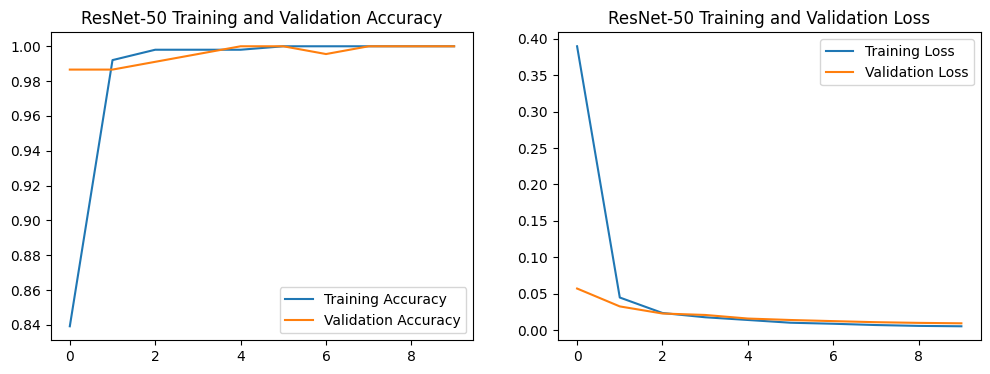

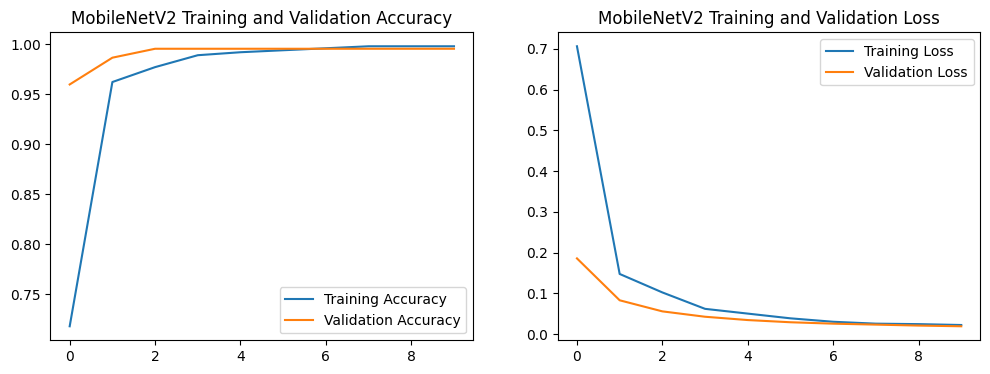

In [5]:
import matplotlib.pyplot as plt

EPOCHS = 10

print("--- Training ResNet-50 ---")
resnet_history = resnet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

print("\n--- Training MobileNetV2 ---")
mobilenet_history = mobilenet_model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

# Function to plot training results
def plot_history(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs_range = range(EPOCHS)

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title(f'{model_name} Training and Validation Accuracy')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title(f'{model_name} Training and Validation Loss')
    plt.show()

plot_history(resnet_history, 'ResNet-50')
plot_history(mobilenet_history, 'MobileNetV2')


Evaluating ResNet-50...

--- ResNet-50 Benchmark Results ---
Test Accuracy: 1.0000
Test Loss: 0.0065
Average Inference Latency per image: 70.48 ms

Classification Report:
              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00        51
       Guava       1.00      1.00      1.00        38
       Mango       1.00      1.00      1.00       118

    accuracy                           1.00       207
   macro avg       1.00      1.00      1.00       207
weighted avg       1.00      1.00      1.00       207



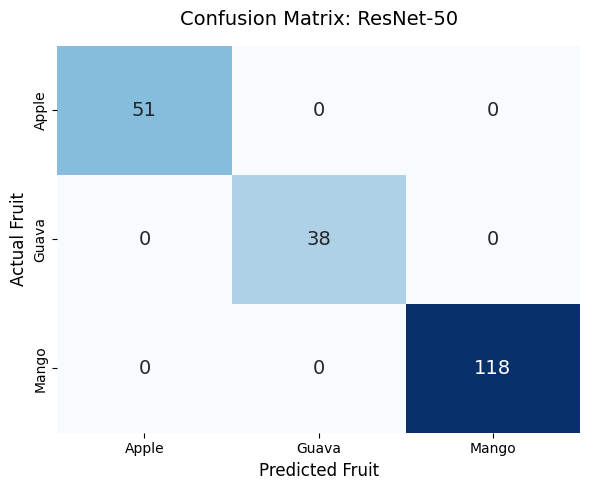


Evaluating MobileNetV2...

--- MobileNetV2 Benchmark Results ---
Test Accuracy: 1.0000
Test Loss: 0.0171
Average Inference Latency per image: 77.31 ms

Classification Report:
              precision    recall  f1-score   support

       Apple       1.00      1.00      1.00        51
       Guava       1.00      1.00      1.00        38
       Mango       1.00      1.00      1.00       118

    accuracy                           1.00       207
   macro avg       1.00      1.00      1.00       207
weighted avg       1.00      1.00      1.00       207



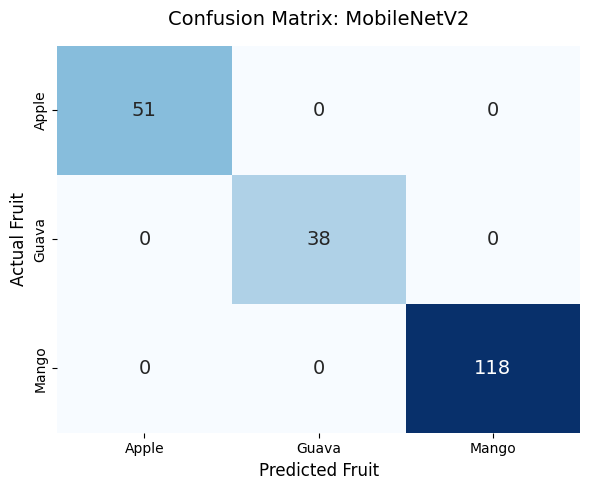

In [6]:
import time
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model(model, dataset, model_name):
    print(f"\n{'='*40}")
    print(f"Evaluating {model_name}...")
    print(f"{'='*40}")

    y_true = []
    y_pred = []
    latencies = []

    # Calculate Latency & get predictions
    for images, labels in dataset:
        y_true.extend(labels.numpy())

        # Measure inference latency per batch
        start_time = time.time()
        preds = model.predict(images, verbose=0)
        end_time = time.time()

        # Latency per image in milliseconds
        batch_latency = (end_time - start_time) / len(images) * 1000
        latencies.append(batch_latency)

        y_pred.extend(np.argmax(preds, axis=1))

    # Calculate standard metrics
    loss, accuracy = model.evaluate(dataset, verbose=0)
    avg_latency = np.mean(latencies)

    print(f"\n--- {model_name} Benchmark Results ---")
    print(f"Test Accuracy: {accuracy:.4f}")
    print(f"Test Loss: {loss:.4f}")
    print(f"Average Inference Latency per image: {avg_latency:.2f} ms")

    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # Generate and Plot the Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names,
                cbar=False,
                annot_kws={"size": 14})

    plt.title(f'Confusion Matrix: {model_name}', fontsize=14, pad=15)
    plt.ylabel('Actual Fruit', fontsize=12)
    plt.xlabel('Predicted Fruit', fontsize=12)
    plt.tight_layout()
    plt.show()

    return accuracy, loss

# Run evaluation and capture the return values for the next cell
resnet_acc, resnet_loss = evaluate_model(resnet_model, test_dataset, "ResNet-50")
mobilenet_acc, mobilenet_loss = evaluate_model(mobilenet_model, test_dataset, "MobileNetV2")

In [7]:
import os

print("--- Selecting the Best Model ---")

# Extract final test metrics for both models
resnet_loss, resnet_acc = resnet_model.evaluate(test_dataset, verbose=0)
print(f"ResNet-50 Test Accuracy: {resnet_acc:.4f} (Loss: {resnet_loss:.4f})")

mobilenet_loss, mobilenet_acc = mobilenet_model.evaluate(test_dataset, verbose=0)
print(f"MobileNetV2 Test Accuracy: {mobilenet_acc:.4f} (Loss: {mobilenet_loss:.4f})")

# Determine the winner
if mobilenet_acc > resnet_acc:
    print("\n🏆 MobileNetV2 is the better model based on accuracy.")
    best_model = mobilenet_model
    best_model_name = "fruit_type_identifier_mobilenetv2.keras"
elif resnet_acc > mobilenet_acc:
    print("\n🏆 ResNet-50 is the better model based on accuracy.")
    best_model = resnet_model
    best_model_name = "fruit_type_identifier_resnet50.keras"
else:
    # Tie-breaker based on lowest validation loss
    if mobilenet_loss < resnet_loss:
        print("\n🏆 Models tied on accuracy. MobileNetV2 selected based on lower loss.")
        best_model = mobilenet_model
        best_model_name = "fruit_type_identifier_mobilenetv2.keras"
    else:
        print("\n🏆 Models tied on accuracy. ResNet-50 selected based on lower loss.")
        best_model = resnet_model
        best_model_name = "fruit_type_identifier_resnet50.keras"

# Save the winning model
best_model.save(best_model_name)
print(f"\nModel successfully saved as: '{best_model_name}'")

# Check file size of the saved model
file_size_mb = os.path.getsize(best_model_name) / (1024 * 1024)
print(f"Saved model file size: {file_size_mb:.2f} MB")

--- Selecting the Best Model ---
ResNet-50 Test Accuracy: 1.0000 (Loss: 0.0065)
MobileNetV2 Test Accuracy: 1.0000 (Loss: 0.0171)

🏆 Models tied on accuracy. ResNet-50 selected based on lower loss.

Model successfully saved as: 'fruit_type_identifier_resnet50.keras'
Saved model file size: 90.68 MB
